# Шаг 6. Настоящий GPT

**ruGPT-3 small** (Сбер, 2021) устроена так же, как наша мини-GPT из сессии 5: эмбеддинги токенов и позиций → блоки
«внимание + MLP» → линейный слой с оценками для каждого токена словаря. Различия — только в масштабе:

| | мини-GPT (сессия 5) | ruGPT-3 small |
|-|--------------------|---------------|
| токены | 75 символов | 50 257 кусочков BPE |
| длина вектора | 128 | 768 |
| блоков | 4 | 12 |
| голов внимания | 4 | 12 |
| контекст | 64 символа | 2048 токенов (несколько страниц) |
| весов | 0,8 млн | 125 млн |
| текст для обучения | «Онегин», 140 тыс. символов | около 80 ГБ: книги, новости, Википедия, форумы |

In [1]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session05 и session06).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session06")  # здесь лежит common.py; модели скачаются в machine_vision/data/hf
    sys.path.insert(0, os.getcwd())
    !pip install -q transformers

In [2]:
import importlib.util
import math

import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F

from common import HERE, load_genres, load_model, load_onegin, load_tokenizer, show

tok = load_tokenizer("gpt")
gpt = load_model("gpt", "lm")
print("устройство модели:", gpt.config.n_layer, "блоков,", gpt.config.n_head, "голов, вектор", gpt.config.n_embd)

устройство модели: 12 блоков, 12 голов, вектор 768


## 1. Какое слово следующее?

Модель выдаёт вероятность для **каждого** из 50 257 токенов. Посмотрим на 10 самых вероятных — так же, как в шаге 6 сессии 5
мы смотрели на самые вероятные символы.

«Мой дядя самых честных» → ·правил 55%, ·людей 8%, ·и 5%, ·слов 3%, , 2%
«Жили-были дед да» → ·баба 68%, ·бабка 21%, ·бабушка 3%, ·баб 1%, ·старуха 1%


«Столица России —» → ·Москва 15%, ·город 7%, ·это 7%, ·Санкт 6%, ·столица 1%


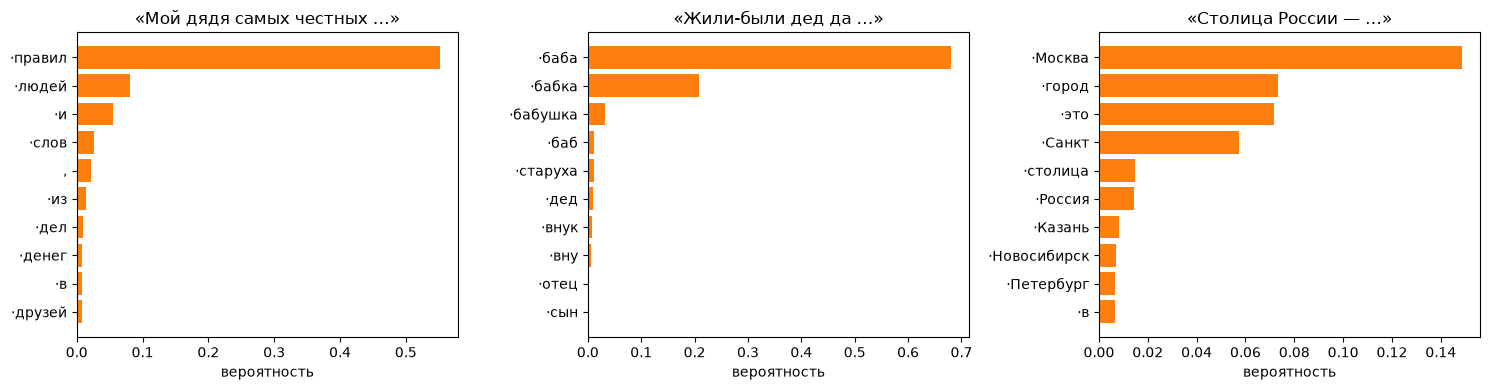

In [3]:
@torch.no_grad()
def next_token_probs(text):
    ids = tok(text, return_tensors="pt")["input_ids"]
    logits = gpt(ids).logits[0, -1]               # оценки для токена после последнего
    return logits.softmax(-1)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, prompt in zip(axes, ["Мой дядя самых честных", "Жили-были дед да", "Столица России —"]):
    probs = next_token_probs(prompt)
    best = probs.topk(10)
    pieces = [repr(tok.decode([i]))[1:-1].replace(" ", "·") for i in best.indices.tolist()]
    ax.barh(pieces[::-1], best.values.tolist()[::-1], color="tab:orange")
    ax.set_title(f"«{prompt} …»")
    ax.set_xlabel("вероятность")
    print(f"«{prompt}» → " + ", ".join(f"{p} {v:.0%}" for p, v in zip(pieces[:5], best.values.tolist())))
plt.tight_layout()
plt.savefig("gpt_next_token.png", dpi=100)
show()

Точка `·` перед кусочком — это пробел: в ruGPT-3 пробел приклеен к началу слова (шаг 1).
Модель уверенно продолжает Пушкина и сказку — эти тексты она видела много раз.

## 2. Как выбирать следующее слово

Модель выдаёт **распределение**, а выбрать из него токен можно по-разному. В сессии 5 (шаг 4) мы знакомились с температурой.
У настоящих моделей способов больше:

| Способ | Как выбирает | Чем плох |
|--------|-------------|----------|
| жадный | всегда самый вероятный | скучно и часто зацикливается |
| температура T | бросаем кубик по вероятностям, поделив логиты на T | при большом T — бессмыслица |
| top-k | кубик только среди k самых вероятных | k приходится подбирать |
| top-p | кубик среди самых вероятных, пока их сумма не достигнет p | — (обычно используют его) |

Функция `generate` из `transformers` повторяет то, что мы делали в сессии 5 вручную: угадать токен → дописать → угадать следующий.

In [4]:
def continue_text(prompt, max_new_tokens=40, seed=0, **how):
    torch.manual_seed(seed)
    ids = tok(prompt, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        out = gpt.generate(ids, max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id,
                           do_sample=bool(how), **how)
    return tok.decode(out[0][ids.shape[1]:])


prompt = "Жили-были дед да баба."
for name, how in [("жадный", {}),
                  ("температура 0.7", {"temperature": 0.7, "top_k": 0}),
                  ("температура 1.5", {"temperature": 1.5, "top_k": 0}),
                  ("top-k = 20", {"top_k": 20}),
                  ("top-p = 0.9", {"top_p": 0.9, "top_k": 0})]:
    print(f"\n--- {name}:\n{prompt}{continue_text(prompt, **how)}")


--- жадный:
Жили-были дед да баба.  И жили они долго и счастливо.  И вот однажды, когда дед и баба были уже далеко, они решили, что пора бы и им отдохнуть.  И решили они, что пора бы и



--- температура 0.7:
Жили-были дед да баба.  Жили-были и умерли.  И все же люди, которые их любили и знали, были несчастны.  Жили-были и умерли.  И все же люди, которые их любили



--- температура 1.5:
Жили-были дед да баба. Про каждое село напутрен монотонно дорогую учительскую краску берестали штандартом красивой руки XV–XVI веков. 2 по правой фигре явственно обозначил Ésylv наносят третью



--- top-k = 20:
Жили-были дед да баба. На самом деле, как оказалось, они не могли жить в одной деревне, а жили в двух-трех домах. В доме на двоих жили только старики.

Бабушка-то, в свою



--- top-p = 0.9:
Жили-были дед да баба. Проспали, влюбились друг в друга. Дурак он, не знаю кто…

Что ж, у мужчин всё отнимется, но у женщин останутся только вторые…

Я


**Что видно:**
- **жадный** выбор быстро начинает повторять одни и те же фразы — как в сессии 5 при температуре около 0
  (при температуре 0.7 повторы тоже появились — это случайность, с другим `seed` их может не быть);
- **температура 1.5** — слова русские, но смысла всё меньше: модель слишком часто выбирает маловероятные токены;
- **top-k** и **top-p** отрезают «хвост» совсем невероятных токенов и оставляют разнообразие. Чат-боты обычно используют
  top-p около 0.9 и температуру 0.7–1.

## 3. Подсказка задаёт жанр

Модель не знает, чего мы хотим. Единственное, чем можно управлять, — **началом текста** (подсказкой, prompt).
По началу модель «догадывается», какой это текст, и продолжает в том же стиле.

In [5]:
for prompt in ["Новости. Сегодня в Москве", "Рецепт блинов. Возьмите", "Дорогой дневник! Сегодня",
               "Инспектор осмотрел комнату и"]:
    print(f"\n{prompt}{continue_text(prompt, max_new_tokens=35, top_p=0.9, top_k=0, temperature=0.8)}")


Новости. Сегодня в Москве начал работу Российский фонд прямых инвестиций (РФПИ). Он начал реализацию своей программы «Построение долгосрочных и краткосрочных отношений с инвесторами» с 1 апреля текущего года.




Рецепт блинов. Возьмите 4 яйца, 2 стакана сахара, 1 ч. л. соли, 1 ст. л. растительного масла, 1 ч. л. соды, 2 ч. л.



Дорогой дневник! Сегодня у меня на работе было очень много интересных, а самое главное, очень хороших людей. Я хочу, чтобы они меня уважали. Я хочу, чтобы они помогали мне решать проблемы



Инспектор осмотрел комнату и начал:

— Надеюсь, ваша клиентка не будет против, если вы уйдете?

— Обязательно, мистер инспектор.




## 4. Помнит ли модель Пушкина наизусть?

Дадим модели начало «Онегина» и попросим продолжить **жадно** (самый вероятный токен каждый раз).
Если модель много раз видела этот текст при обучении, она может воспроизвести его дословно.

In [6]:
start = "Мой дядя самых честных правил,\nКогда не в шутку занемог,\n"
print(start + continue_text(start, max_new_tokens=60))

Мой дядя самых честных правил,
Когда не в шутку занемог,
И в дом его не пустили,
И в дом его не пустили,
И в дом его не пустили,
И в дом его не пустили,
И в дом его не пустили,
И в дом его не пустили,
И в дом его не пустили,
И в дом его


Модель **не помнит** роман: первую строку она продолжает уверенно (пункт 1: «правил» — 55%), но дальше сочиняет своё,
а жадный выбор ещё и зацикливается на одной строке. 125 млн весов не хватает, чтобы запомнить все прочитанные книги.
Большие модели с сотнями миллиардов весов известные стихи помнят — и тогда сравнивать модели на таком тексте нечестно:
одна его учила, другая — нет. Поэтому в следующем пункте мы проверим модели ещё и на тексте, которого не видела ни одна из них.

## 5. Сравниваем с мини-GPT: loss на символ

В сессии 5 мини-GPT получила loss ≈ 1.89 на проверочной части «Онегина» (последние 10% романа). Сравним с ruGPT-3.

**Проблема:** loss мини-GPT — на **символ**, а у ruGPT-3 — на **токен** (кусочек слова в 3–4 символа). Угадать токен труднее,
чем символ, поэтому числа напрямую сравнивать нельзя. Решение: сложить loss всех токенов и поделить на **число символов**.
Получится «сколько штрафа в среднем приходится на символ» — у обеих моделей одна и та же мера.

Сравним на двух текстах:
- проверочная часть «Онегина» — ruGPT-3, возможно, видела роман при обучении (хотя наизусть не помнит);
- стихи из `genres.csv` — их написали для курса, и их **не видела ни одна** из моделей.

In [7]:
@torch.no_grad()
def gpt_loss_per_char(text, window=512):
    """Сумма loss всех токенов текста / число символов. Длинный текст режем на куски по window токенов."""
    ids = tok(text, return_tensors="pt")["input_ids"][0]
    total = 0.0
    for i in range(0, len(ids) - 1, window):
        chunk = ids[max(0, i - 1):i + window].unsqueeze(0)          # +1 токен слева: первый токен куска тоже угадываем
        logits = gpt(chunk).logits
        total += F.cross_entropy(logits[0, :-1], chunk[0, 1:], reduction="sum").item()
    return total / len(text)


def load_mini_gpt():
    """Мини-GPT из сессии 5 (session05/gpt.pt) или None, если её ещё не обучили."""
    path = HERE.parent / "session05" / "common.py"
    spec = importlib.util.spec_from_file_location("session05_common", path)
    s5 = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(s5)
    if not (s5.HERE / "gpt.pt").exists():
        return None, None
    return s5.load_gpt("gpt")


@torch.no_grad()
def mini_loss_per_char(model, mini_tok, text, block=64):
    """Средний loss мини-GPT на символ: куски по block символов, как при её обучении."""
    text = "".join(ch for ch in text if ch in mini_tok.stoi)        # символов, которых мини-GPT не знает, выбрасываем
    data = torch.tensor(mini_tok.encode(text))
    total, count = 0.0, 0
    for i in range(0, len(data) - 1, block):
        x = data[i:i + block].unsqueeze(0)
        y = data[i + 1:i + block + 1].unsqueeze(0)
        x = x[:, :y.shape[1]]
        logits = model(x)
        logits = logits[0] if isinstance(logits, tuple) else logits
        total += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1), reduction="sum").item()
        count += y.numel()
    return total / count


onegin = load_onegin()
onegin_val = onegin[int(0.9 * len(onegin)):]
new_poems = "\n\n".join(r["text"] for r in load_genres() if r["genre"] == "стихи")
texts = {"«Онегин», последние 10%": onegin_val, "новые стихи из genres.csv": new_poems}

mini, mini_tok = load_mini_gpt()
results = {}
for name, text in texts.items():
    results[name] = {"ruGPT-3": gpt_loss_per_char(text)}
    if mini is not None:
        results[name]["мини-GPT"] = mini_loss_per_char(mini, mini_tok, text)
    print(f"{name:28s} ({len(text)} символов): " + ", ".join(f"{m} {v:.2f}" for m, v in results[name].items()))
if mini is None:
    print("Нет session05/gpt.pt — выполните шаг 6 сессии 5, чтобы сравнить с мини-GPT")
print(f"для сравнения, угадывание наугад среди 75 символов: {math.log(75):.2f}")

«Онегин», последние 10%      (13821 символов): ruGPT-3 1.19, мини-GPT 1.96


новые стихи из genres.csv    (2141 символов): ruGPT-3 0.99, мини-GPT 2.30
для сравнения, угадывание наугад среди 75 символов: 4.32


**Как читать:** чем меньше число, тем лучше модель предсказывает текст. Разница в 1 означает, что модель в e ≈ 2,7 раза
увереннее в правильном символе.

- На «Онегине» ruGPT-3 намного лучше мини-GPT. (У мини-GPT здесь чуть больше, чем 1.89 из сессии 5: мы режем текст
  на куски по 64 символа, и в начале каждого куска у неё мало контекста.)
- На **новых** стихах ruGPT-3 ещё лучше, чем на «Онегине»: они написаны простым современным языком, который она хорошо знает.
  А мини-GPT на новых стихах хуже: она знает только язык «Онегина», и стихи про туман и листопад для неё «чужие».
- Это и есть главное преимущество больших моделей: они обобщают на **любые** тексты, а не только на тот, на котором учились.

## 6. «Удивление» модели: подсвечиваем неожиданные слова

Loss отдельного токена — это мера **удивления** модели: −log P(токен). Маленький loss — «так и думала»,
большой — «вот это неожиданно». Раскрасим текст: чем краснее кусочек, тем сильнее удивилась модель.

На этом построены проверка орфографии (опечатка — очень неожиданный токен) и детекторы «текст написан нейросетью»
(текст нейросети подозрительно **неудивителен** для другой нейросети).

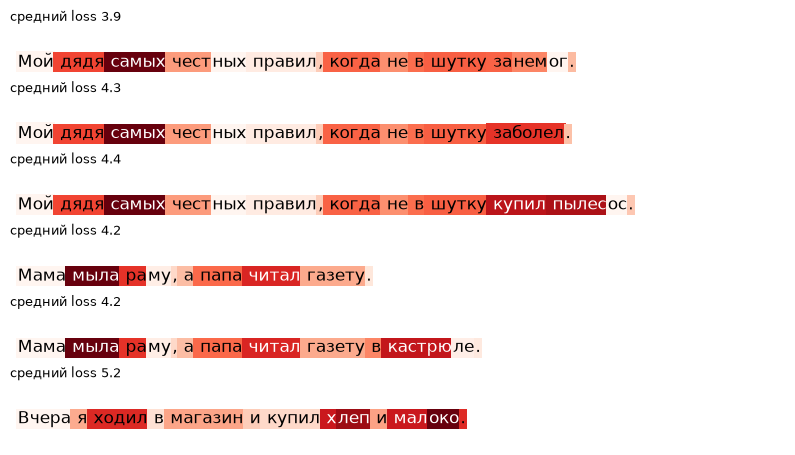

Мой дядя самых честных правил, когда не в шутку занемог.          самое неожиданное: «шутку» 5.3, «когда» 5.2
Мой дядя самых честных правил, когда не в шутку заболел.          самое неожиданное: «заболел» 6.5, «шутку» 5.3
Мой дядя самых честных правил, когда не в шутку купил пылесос.    самое неожиданное: «пылес» 8.5, «купил» 8.0
Мама мыла раму, а папа читал газету.                              самое неожиданное: «читал» 7.0, «папа» 5.0
Мама мыла раму, а папа читал газету в кастрюле.                   самое неожиданное: «кастрю» 7.8, «читал» 7.0
Вчера я ходил в магазин и купил хлеп и малоко.                    самое неожиданное: «око» 10.3, «леп» 8.9


In [8]:
@torch.no_grad()
def surprise(text):
    """Список (кусочек текста, удивление) для всех токенов, кроме первого."""
    ids = tok(text, return_tensors="pt")["input_ids"]
    logp = gpt(ids).logits[0, :-1].log_softmax(-1)
    s = -logp[torch.arange(ids.shape[1] - 1), ids[0, 1:]]
    pieces = [tok.decode([i]) for i in ids[0].tolist()]
    return [(pieces[0], 0.0)] + list(zip(pieces[1:], s.tolist()))


def draw_surprise(ax, text):
    """Рисует текст, фон каждого кусочка — по удивлению (0 — белый, 10 и больше — тёмно-красный)."""
    items = surprise(text)
    prev = None
    for piece, s in items:
        style = dict(fontsize=12, va="bottom", color="white" if s > 7 else "black",
                     bbox=dict(boxstyle="square,pad=0.1", facecolor=plt.cm.Reds(min(s / 10, 1.0)), edgecolor="none"))
        if prev is None:
            prev = ax.text(0.01, 0.3, piece, transform=ax.transAxes, **style)
        else:   # следующий кусочек приклеиваем к правому краю предыдущего
            prev = ax.annotate(piece, xy=(1, 0), xycoords=prev, xytext=(1, 0), textcoords="offset points", **style)
    ax.axis("off")
    mean = sum(s for _, s in items[1:]) / max(1, len(items) - 1)
    ax.set_title(f"средний loss {mean:.1f}", fontsize=9, loc="left")


examples = [
    "Мой дядя самых честных правил, когда не в шутку занемог.",
    "Мой дядя самых честных правил, когда не в шутку заболел.",
    "Мой дядя самых честных правил, когда не в шутку купил пылесос.",
    "Мама мыла раму, а папа читал газету.",
    "Мама мыла раму, а папа читал газету в кастрюле.",
    "Вчера я ходил в магазин и купил хлеп и малоко.",
]
fig, axes = plt.subplots(len(examples), 1, figsize=(10, 0.9 * len(examples)))
for ax, text in zip(axes, examples):
    draw_surprise(ax, text)
plt.savefig("gpt_surprise.png", dpi=100)
show()

for text in examples:
    top = sorted(surprise(text)[4:], key=lambda t: -t[1])[:2]      # первые токены пропускаем: там у модели нет контекста
    print(f"{text:65s} самое неожиданное: " + ", ".join(f"«{p.strip()}» {s:.1f}" for p, s in top))

Первые слова каждой фразы красные: в начале у модели ещё нет контекста, и угадать слово трудно («Мама **мыла**» —
откуда модели знать, что делала мама?). Поэтому при поиске самых неожиданных кусочков первые четыре токена пропускаем.

Дальше неожиданнее всего — «купил пылесос» вместо «занемог», «в кастрюле» и опечатки «хлеп», «малоко»:
модели пришлось собирать их из странных кусочков («х» + «леп», «мал» + «око»), и каждый кусочек неожиданный.

## Попробуйте сами

1. Сравните генерацию с температурой 0.3, 0.7, 1.0, 2.0 на одной и той же подсказке. С какой температуры текст становится бессмысленным?
2. Подберите подсказку, после которой модель пишет: а) стихи, б) диалог, в) список покупок.
3. Проверьте, знает ли модель наизусть другие известные стихи («Белеет парус одинокий», «Я помню чудное мгновенье»).
4. Напишите предложение с ошибкой и без. На сколько вырос средний loss?
5. Возьмите две фразы — свою и сгенерированную моделью. У какой средний loss ниже? Можно ли так отличить текст нейросети?